In [ ]:
!nvidia-smi

Tue May 20 03:27:09 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.124.06             Driver Version: 570.124.06     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P0             48W /  400W |       1MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

# Install YOLOv5


In [ ]:
# clone YOLOv5 repository
%cd /content
!git clone https://github.com/ultralytics/yolov5

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 17485, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 17485 (delta 78), reused 30 (delta 30), pack-reused 17378 (from 3)
Receiving objects: 100% (17485/17485), 16.35 MiB | 30.55 MiB/s, done.
Resolving deltas: 100% (11989/11989), done.


In [ ]:
# install dependencies as necessary
!pip install -r requirements.txt
!pip uninstall wandb -qy  # deprecated dependency
import torch

from IPython.display import Image, clear_output  # to display images

# clear_output()
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
Setup complete. Using torch 2.5.1+cu121 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', major=8, minor=0, total_memory=40442MB, multi_processor_count=108, uuid=2f3b0ebe-e004-5e63-6631-879b01501947, L2_cache_size=40MB)


In [ ]:
%cd /content/yolov5


!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("yolv5-detection")
version = project.version(1)
dataset = version.download("yolov5")


/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 91.7 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 1.13.0 requires anyio<5.0.0,>=4.8.0, but you have anyio 3.7.1 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to YOLV5-Detection-1 in yolov5pytorch:: 100%|██████████| 6860/6860 [00:00<00:00, 7652.02it/s]


In [ ]:
!pip uninstall -y ray
!pip uninstall ray tune-sklearn

Found existing installation: ray 2.33.0
Uninstalling ray-2.33.0:
  Successfully uninstalled ray-2.33.0


In [ ]:
# train yolov5s on custom data for 25 epochs
# time its performance
%%time
%cd /content/yolov5/
!python train.py \
  --img 416 \
  --batch 16 \
  --epochs 300 \
  --data {dataset.location}/data.yaml \
  --weights yolov5s.pt \
  --name yolov5s_results  \
  --cache

Streaming output truncated to the last 5000 lines.
  with torch.cuda.amp.autocast(amp):
    286/299      2.04G    0.04141    0.07512   0.004017        589        416:  96% 180/188 [00:13<00:00, 13.50it/s]/content/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    286/299      2.04G    0.04141    0.07516   0.004037        801        416:  96% 180/188 [00:13<00:00, 13.50it/s]/content/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    286/299      2.04G    0.04139    0.07511   0.004025        613        416:  97% 182/188 [00:13<00:00, 13.82it/s]/content/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(

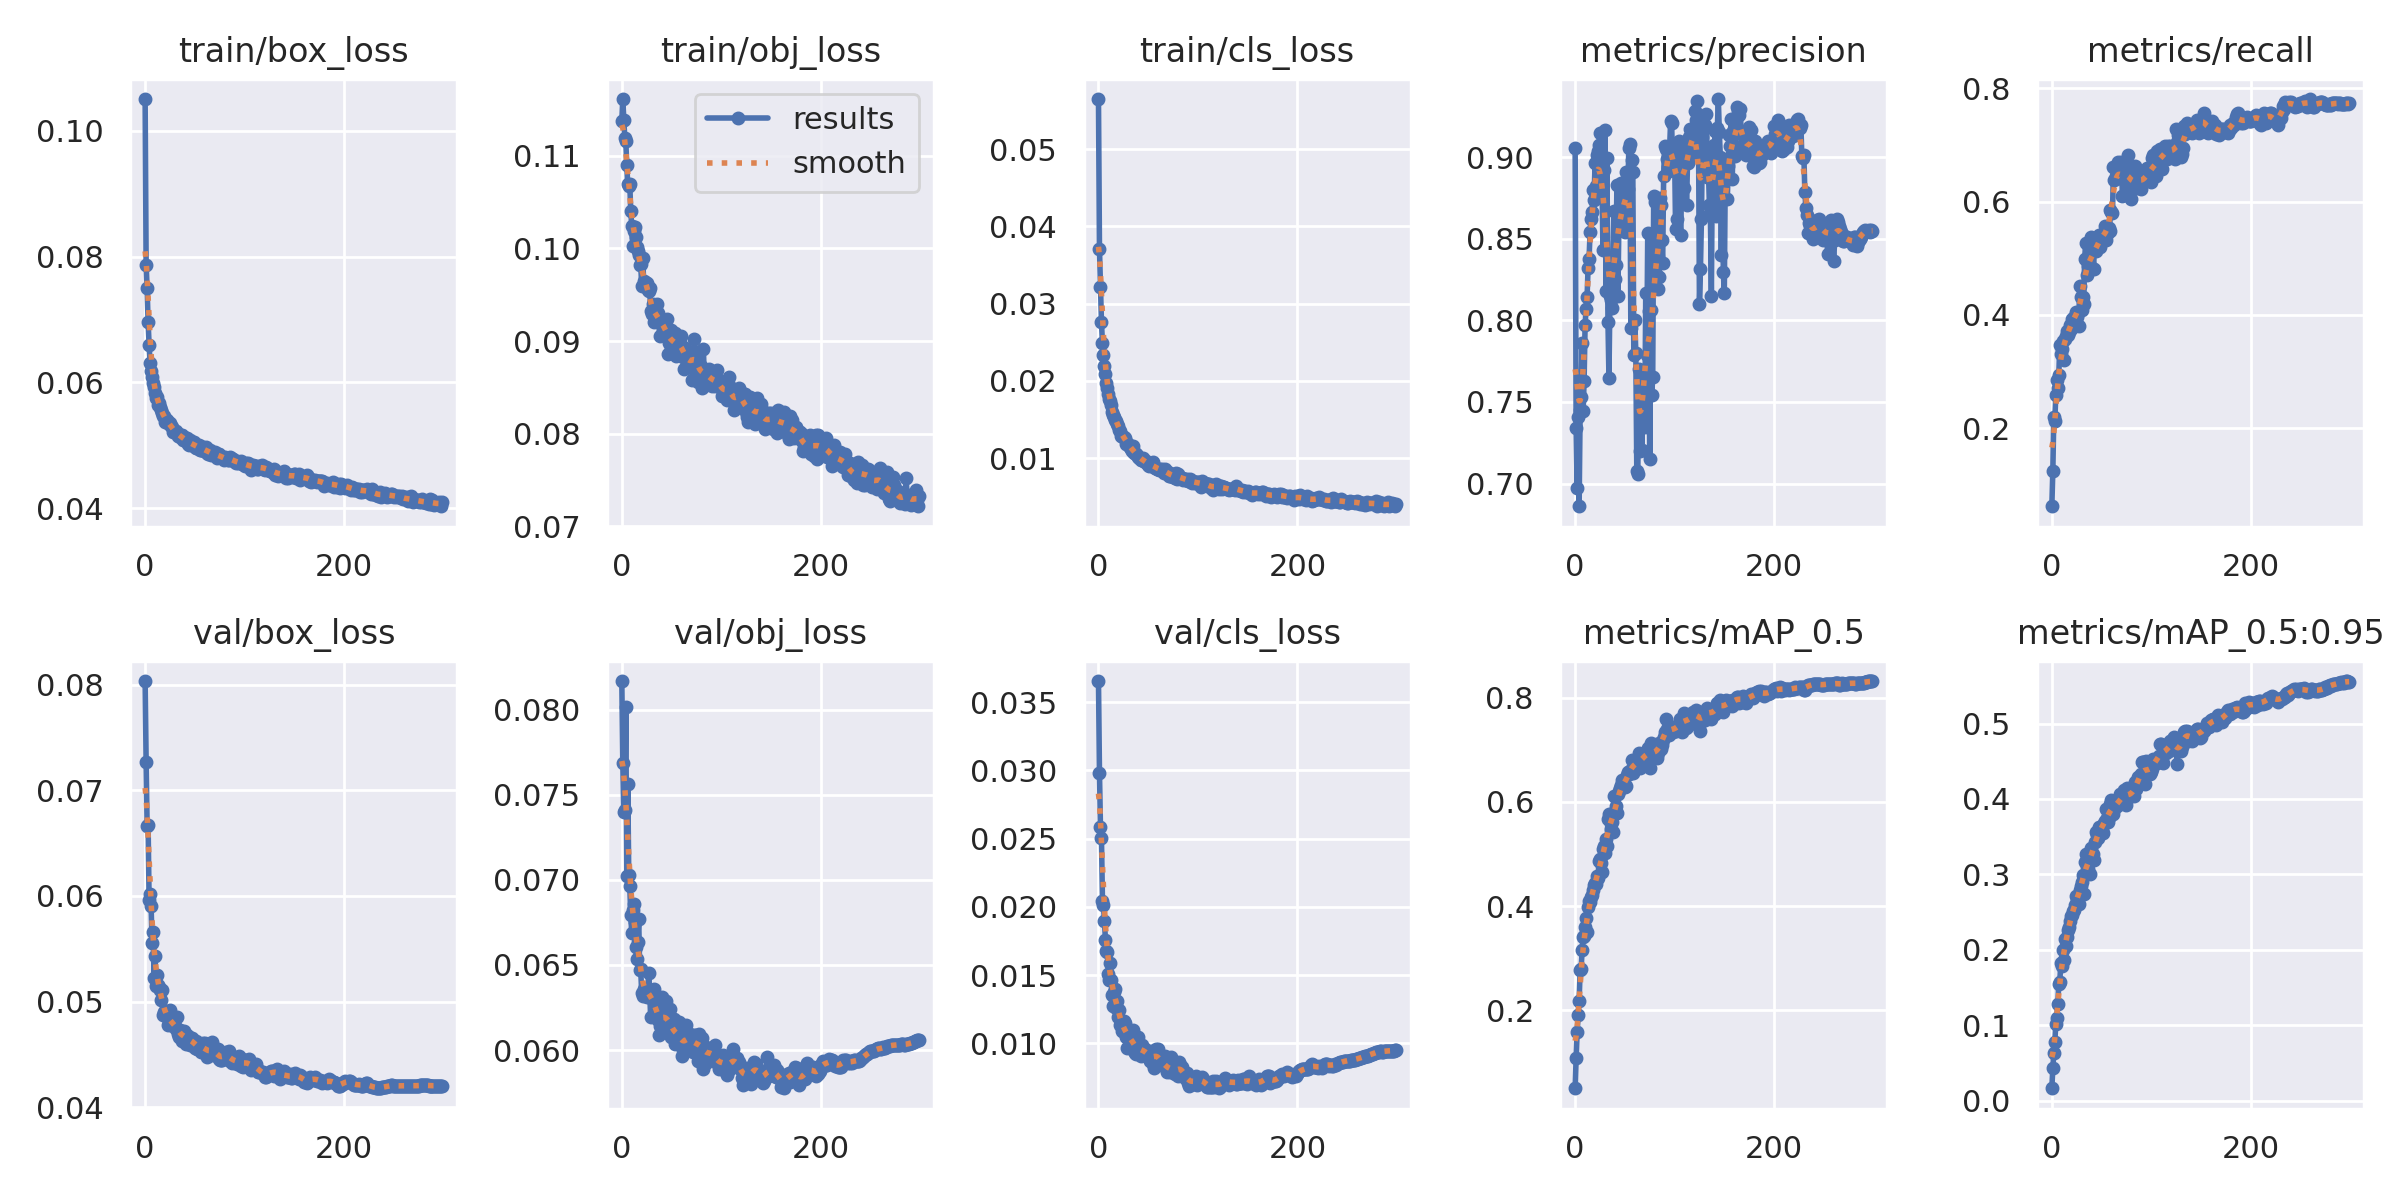

In [ ]:
from utils.plots import plot_results  # plot results.txt as results.png
Image(filename='/content/yolov5/runs/train/yolov5s_results/results.png', width=1000)

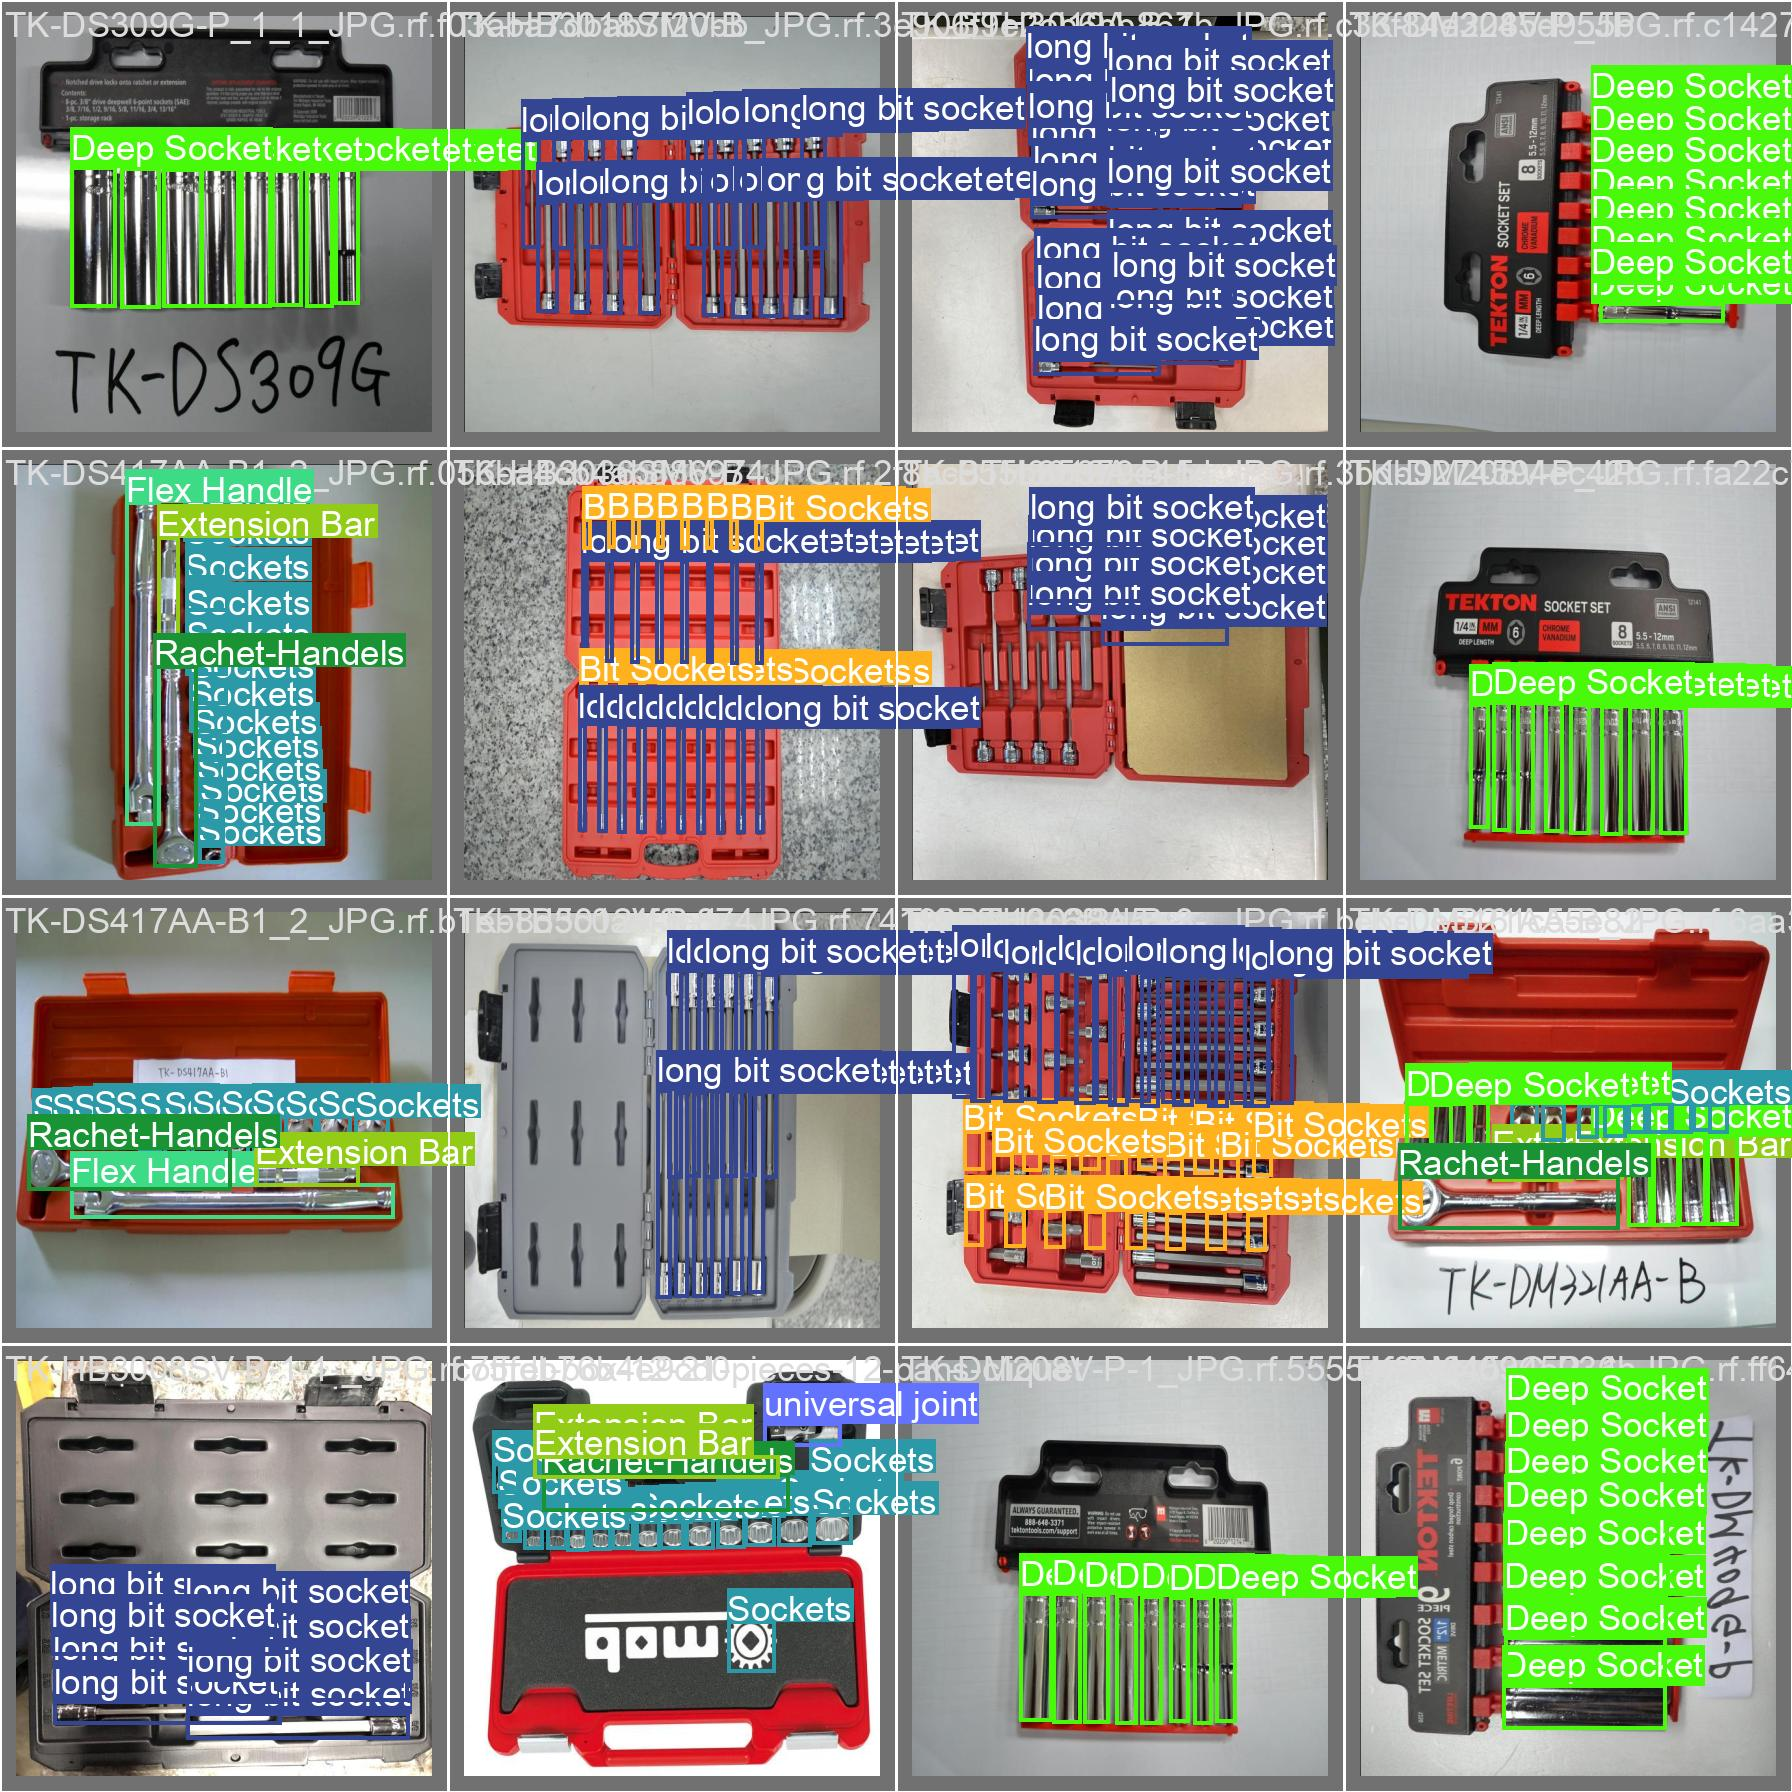

In [ ]:
Image(filename='/content/yolov5/runs/train/yolov5s_results/val_batch0_labels.jpg', width=900)

GROUND TRUTH AUGMENTED TRAINING DATA:


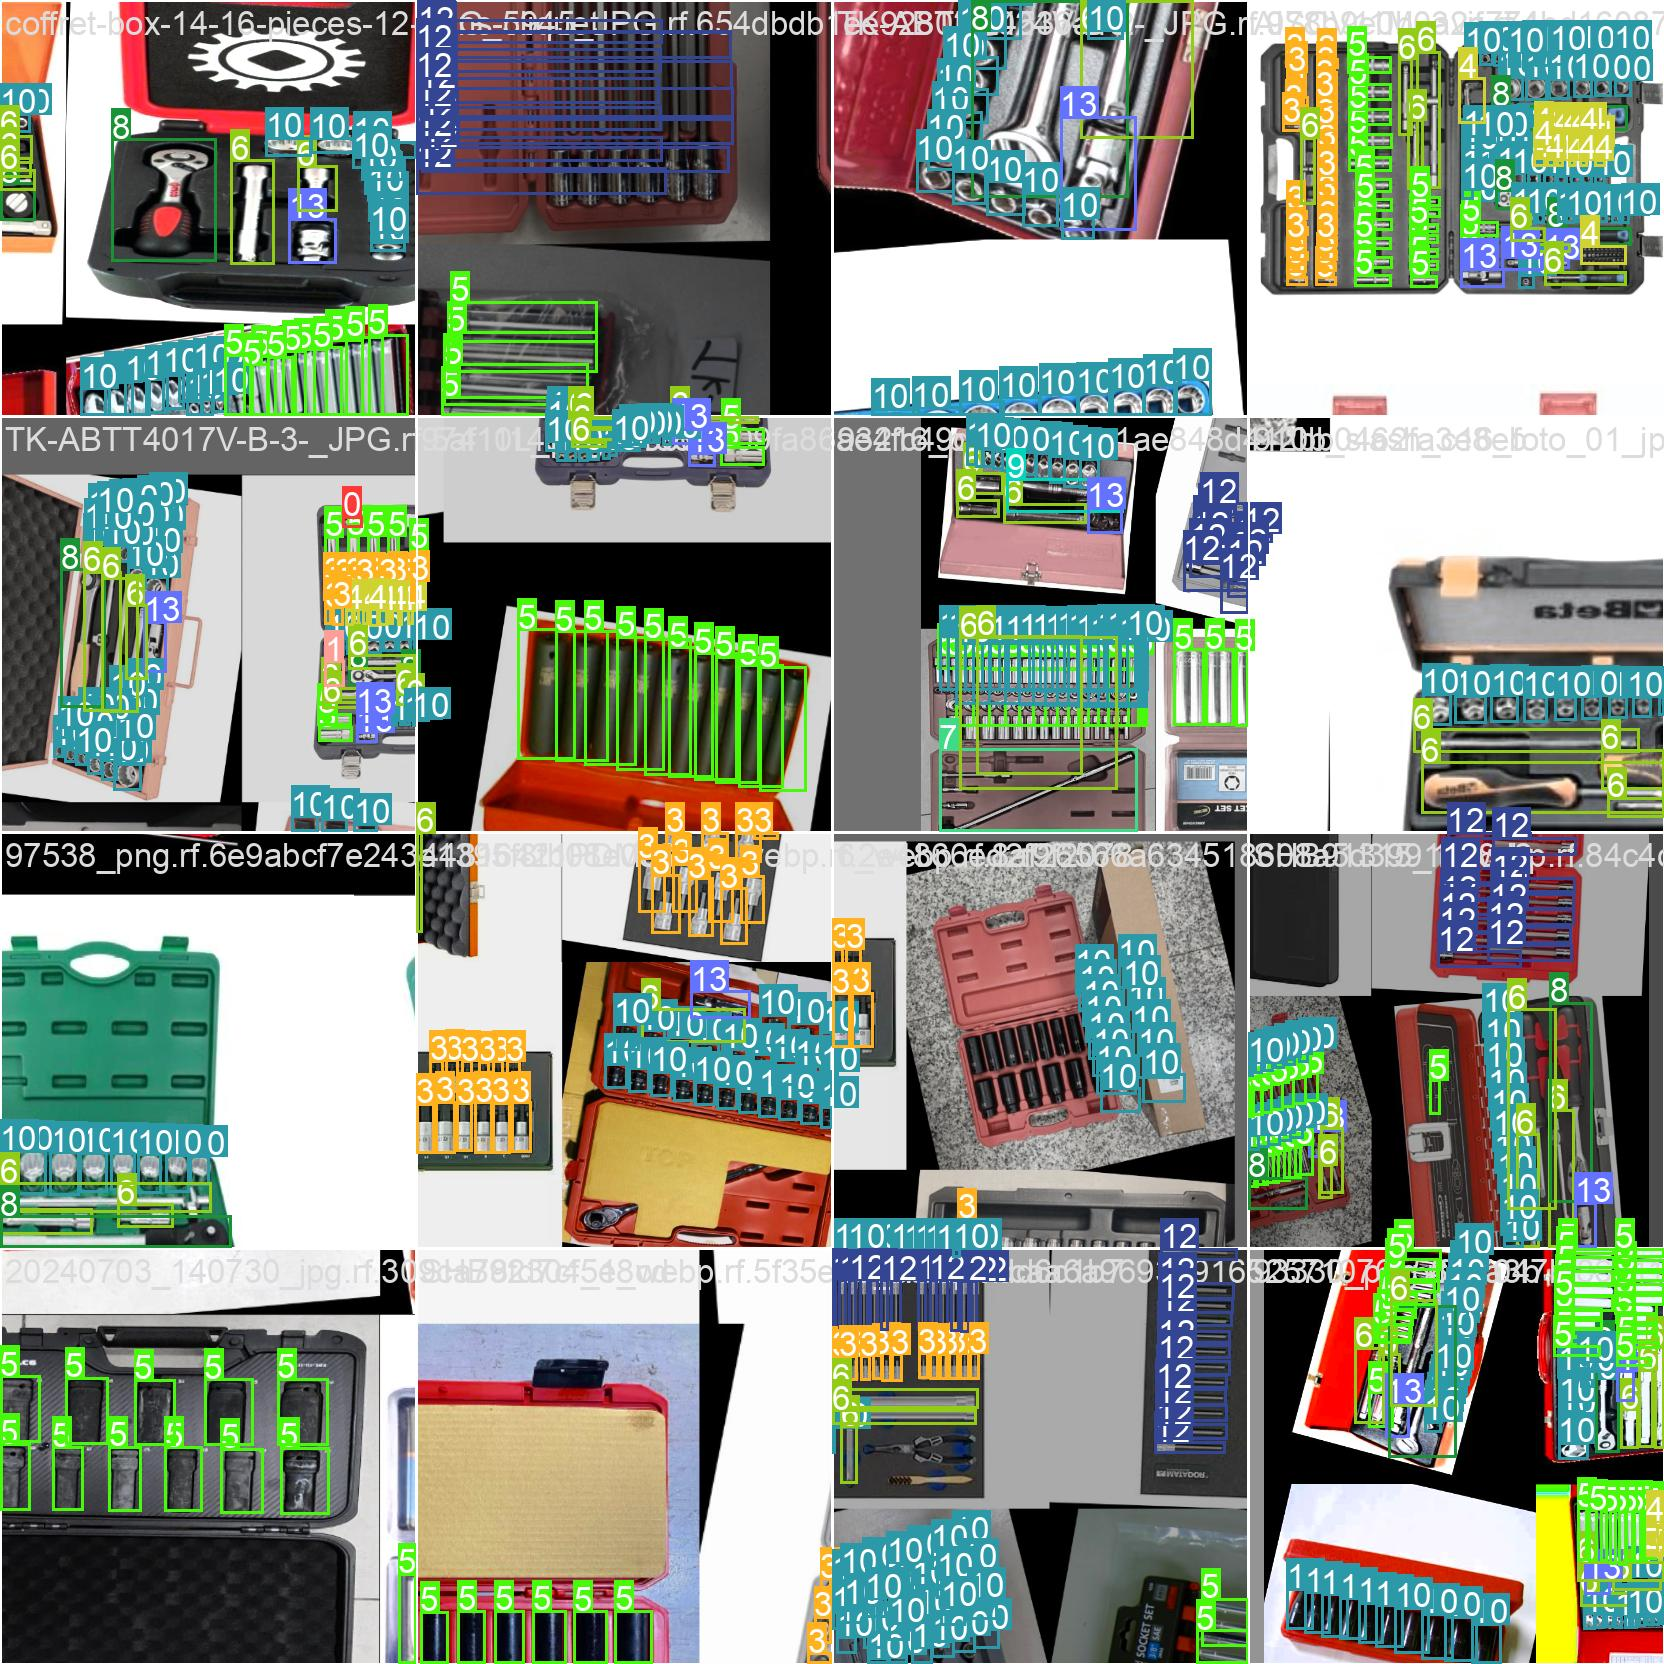

In [ ]:
# print out an augmented training example
print("GROUND TRUTH AUGMENTED TRAINING DATA:")
Image(filename='/content/yolov5/runs/train/yolov5s_results/train_batch0.jpg', width=900)

# Run Inference With Trained Weights

Next, we can run inference with a pretrained checkpoint on all images in the `test/images` folder to understand how our model performs on our test set.

In [ ]:
# trained weights are saved by default in our weights folder
%ls runs/

train/


In [ ]:
%ls runs/train/yolov5s_results/weights

best.pt  last.pt


In [ ]:
%cd /content/yolov5/
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.35 --source {dataset.location}/test/images/

/content/yolov5
detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/yolov5/YOLV5-Detection-1/test/images/, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.35, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-418-ga493afe1 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)

Fusing layers... 
Model summary: 157 layers, 7047883 parameters, 0 gradients, 15.9 GFLOPs
image 1/141 /content/yolov5/YOLV5-Detection-1/test/images/1-2-drive-flat-socket-spanners-500x500_webp.rf.334e032ed87e1e8545dd1c892b9ef7f9.jpg: 416x416 3 Extension Bars, 10 Socketss, 6.6ms
image 2/141 /content/yolov5/YOLV5-Detection-1/test/images/

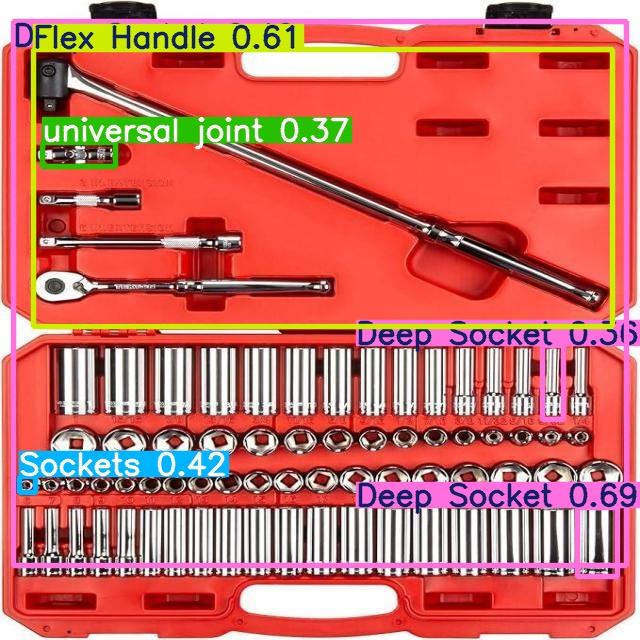

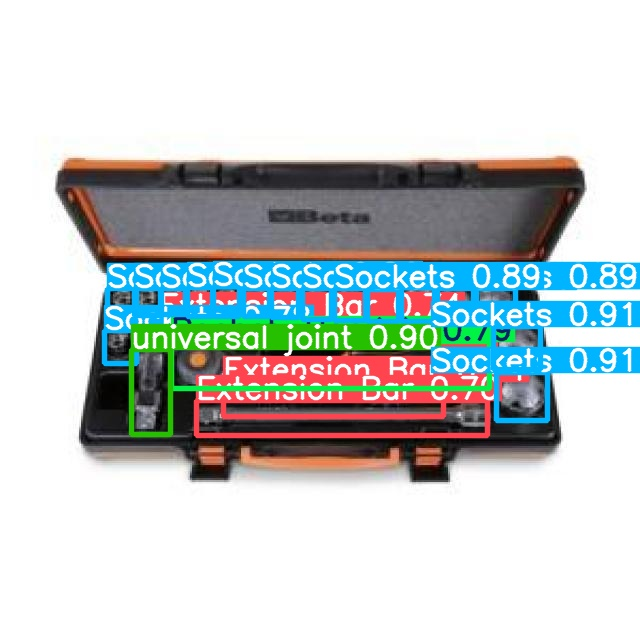

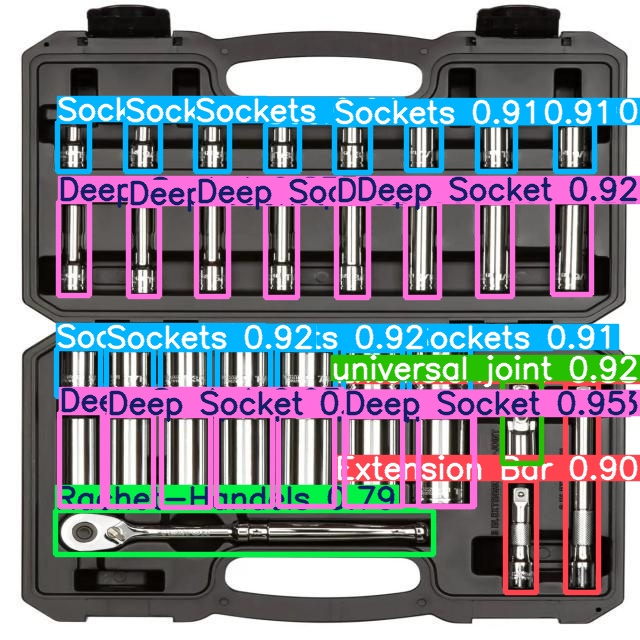

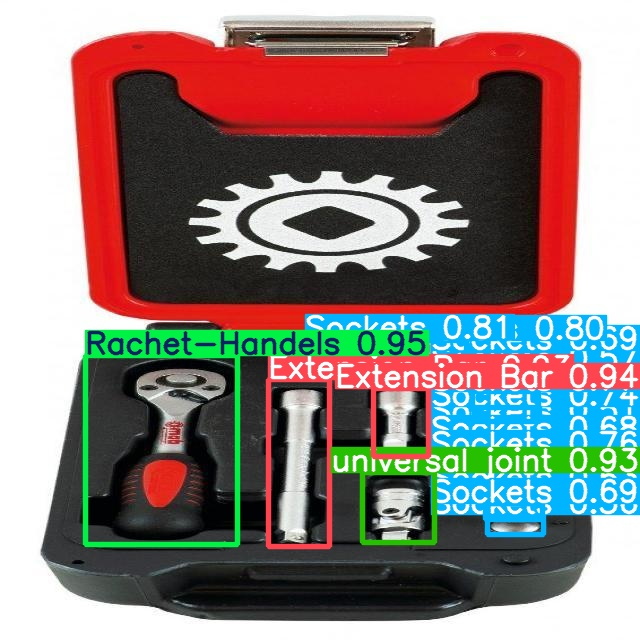

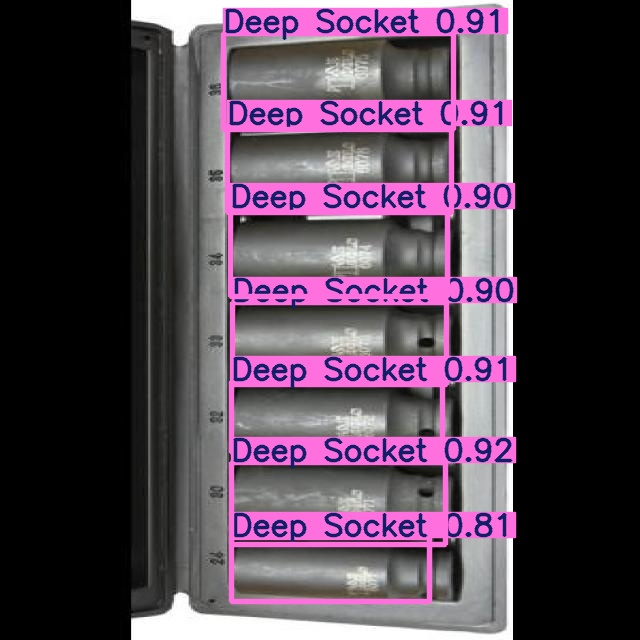

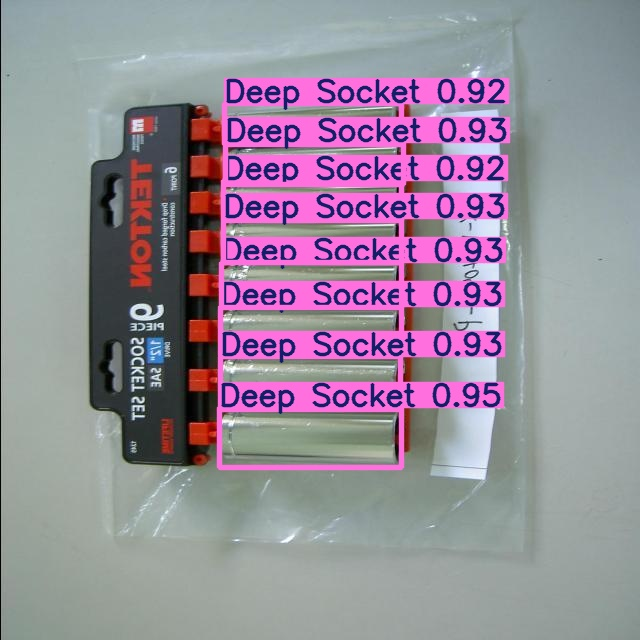

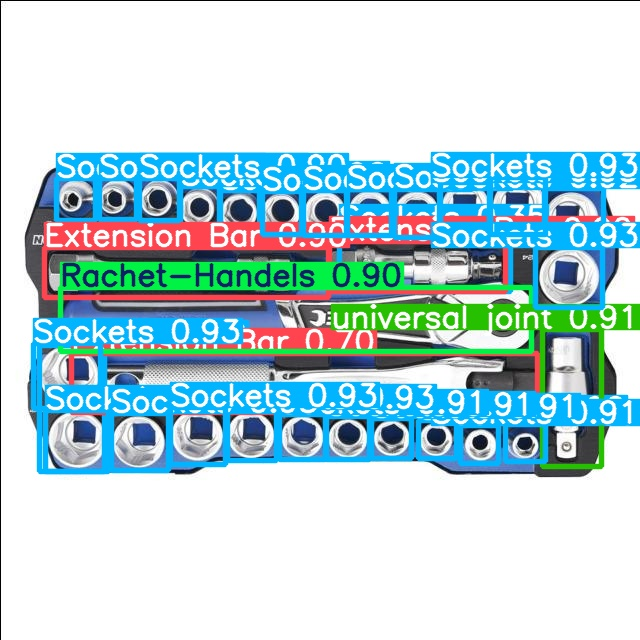

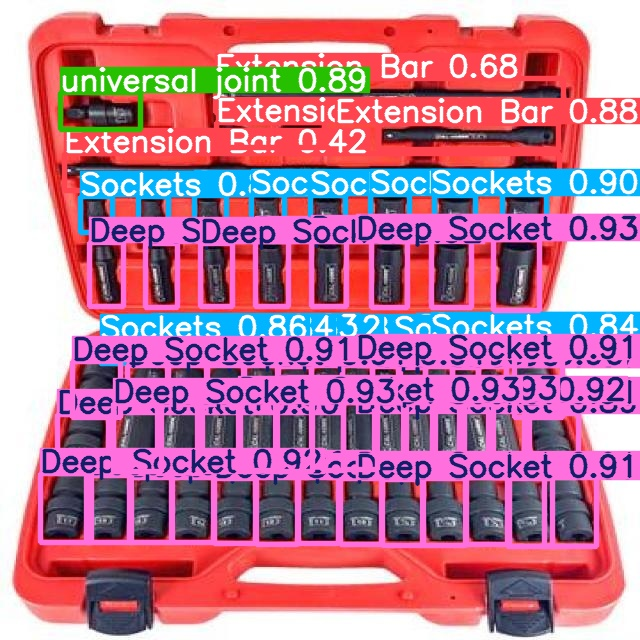

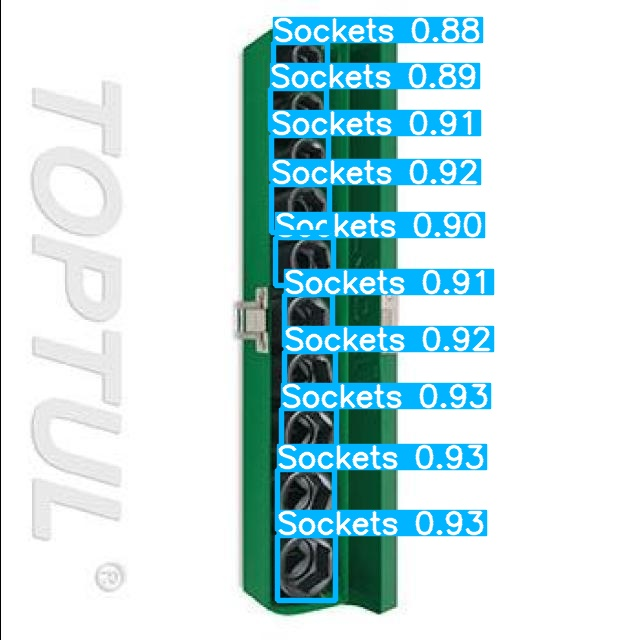

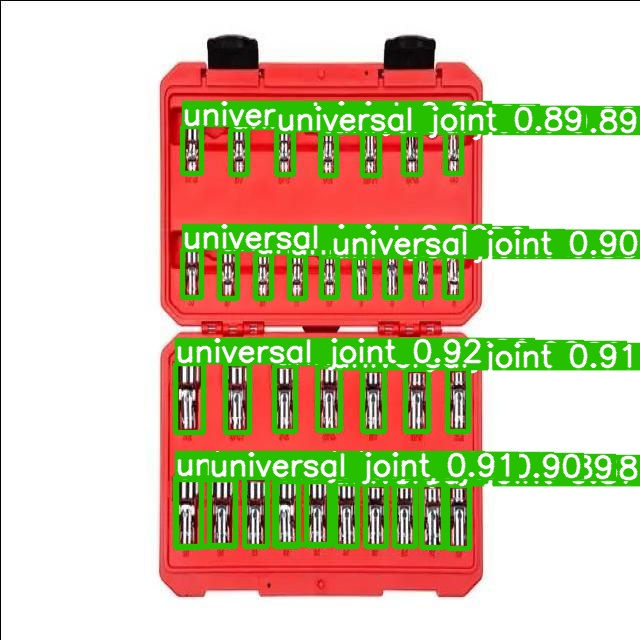

In [ ]:
import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/yolov5/runs/detect/exp/*.jpg')[:10]: #assuming JPG
    display(Image(filename=imageName))

In [ ]:
import torch
import os
import numpy as np
from PIL import Image

def bbox_iou(box1, box2):
    # box1, box2: arrays of shape [4] in xyxy format
    # Calculate IoU of box1 to box2
    inter_x1 = max(box1[0], box2[0])
    inter_y1 = max(box1[1], box2[1])
    inter_x2 = min(box1[2], box2[2])
    inter_y2 = min(box1[3], box2[3])

    inter_area = max(inter_x2 - inter_x1, 0) * max(inter_y2 - inter_y1, 0)
    box1_area = (box1[2]-box1[0])*(box1[3]-box1[1])
    box2_area = (box2[2]-box2[0])*(box2[3]-box2[1])
    union_area = box1_area + box2_area - inter_area

    if union_area == 0:
        return 0
    return inter_area / union_area

def evaluate_model(model, images_dir, labels_dir, iou_thresh=0.5):
    TP = 0
    FP = 0
    FN = 0

    image_files = sorted([f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))])

    for img_file in image_files:
        img_path = os.path.join(images_dir, img_file)
        results = model(img_path)

        preds = results.xyxy[0].cpu().numpy()  # predicted boxes in absolute xyxy format
        pred_boxes = preds[:, :4]
        pred_classes = preds[:, 5].astype(int)

        label_file = img_file.rsplit('.', 1)[0] + '.txt'
        label_path = os.path.join(labels_dir, label_file)

        if not os.path.exists(label_path):
            print(f"Label file not found for {img_file}, skipping...")
            continue

        # Load image size to convert normalized gt boxes
        img = Image.open(img_path)
        img_width, img_height = img.size

        with open(label_path, 'r') as f:
            gt_lines = f.readlines()

        gt_boxes = []
        gt_classes = []

        for line in gt_lines:
            parts = line.strip().split()
            cls = int(parts[0])
            x_center_norm, y_center_norm, w_norm, h_norm = map(float, parts[1:5])

            # Convert normalized to absolute coordinates
            x_center = x_center_norm * img_width
            y_center = y_center_norm * img_height
            w = w_norm * img_width
            h = h_norm * img_height

            x1 = x_center - w/2
            y1 = y_center - h/2
            x2 = x_center + w/2
            y2 = y_center + h/2

            gt_boxes.append([x1, y1, x2, y2])
            gt_classes.append(cls)

        gt_boxes = np.array(gt_boxes)
        gt_classes = np.array(gt_classes)

        matched_gt = set()
        matched_pred = set()

        # Match predictions to ground truths by IoU and class
        for pred_idx, (pb, pc) in enumerate(zip(pred_boxes, pred_classes)):
            ious = np.array([bbox_iou(pb, gt_boxes[gt_idx]) if pc == gt_classes[gt_idx] else 0 for gt_idx in range(len(gt_boxes))])
            max_iou_idx = ious.argmax() if len(ious) > 0 else -1
            max_iou = ious[max_iou_idx] if len(ious) > 0 else 0

            if max_iou >= iou_thresh and max_iou_idx not in matched_gt:
                TP += 1
                matched_gt.add(max_iou_idx)
                matched_pred.add(pred_idx)

        FP += len(pred_boxes) - len(matched_pred)
        FN += len(gt_boxes) - len(matched_gt)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    accuracy = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0

    print(f"True Positives (TP): {TP}")
    print(f"False Positives (FP): {FP}")
    print(f"False Negatives (FN): {FN}")
    print(f"Precision: {precision*100:.2f}%")
    print(f"Recall: {recall*100:.2f}%")
    print(f"Overall Accuracy (TP/(TP+FP+FN)): {accuracy*100:.2f}%")

if __name__ == "__main__":
    # Load YOLOv5 model (update the path if needed)
    model = torch.hub.load('ultralytics/yolov5', 'custom', path='runs/train/yolov5s_results/weights/best.pt', force_reload=True)

    images_dir = '/content/yolov5/YOLV5-Detection-1/test/images'  # Update if your images folder path is different
    labels_dir = '/content/yolov5/YOLV5-Detection-1/test/labels'  # Update if your labels folder path is different

    evaluate_model(model, images_dir, labels_dir, iou_thresh=0.5)


Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to /root/.cache/torch/hub/master.zip
YOLOv5 🚀 v7.0-418-ga493afe1 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)

Fusing layers... 
Model summary: 157 layers, 7047883 parameters, 0 gradients, 15.9 GFLOPs
Adding AutoShape... 
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)

True Positives (TP): 4044
False Positives (FP): 726
False Negatives (FN): 395
Precision: 84.78%
Recall: 91.10%
Overall Accuracy (TP/(TP+FP+FN)): 78.30%


`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.


In [ ]:
accuracy = 83.16%